# Phase 1 · Lesson 1: NumPy, the Language of Machine Learning
**ML Engineer Journey · Benson M. Merita**

**Goal:** see that a machine-learning model is, underneath, *linear algebra on arrays*. By the end you will have written the three core pieces of nearly every ML algorithm, using NumPy only:

1. **Predict:** $\hat{y} = Xw + b$
2. **Measure error:** the Mean Squared Error (MSE)
3. **Find the direction to improve:** the gradient $\nabla_w L$

Then you'll check your work against scikit-learn.

| Section | What you get |
|---|---|
| 1 · Intuition | Why ML needs arrays |
| 2 · The math | Matrix form of prediction, loss and gradient |
| 3 · From scratch | NumPy: shapes, indexing, axes, broadcasting, vectorisation, predict / MSE / gradient |
| 4 · With libraries | scikit-learn's `StandardScaler`, `LinearRegression`, `mean_squared_error` |
| 5 · Dataset | Diabetes progression (scikit-learn built-in) |
| 6 · Exercises | 5 tasks, easy → challenging |
| 7 · Mini-quiz | 4 questions |
| 8 · Mistakes & interviews | What trips people up, and what gets asked |
| 🎬 Demo | Charts for your post |

---
## 1 · Intuition

Imagine you're a clinic analyst with a spreadsheet: **one row per patient**, **one column per measurement** (age, BMI, blood pressure, …). You want to predict how much a patient's disease will progress over the next year.

The simplest sensible recipe is to **give each measurement an importance score (a weight), multiply, and add up**:

> progression ≈ 0.9 × BMI + 0.4 × blood pressure − 0.1 × age + …

"Training" a model means **finding the best weights**. To do that, a computer has to:
- compute this weighted sum for **every patient** (that's thousands or millions of rows),
- check **how wrong** it is,
- nudge the weights in the direction that makes it **less wrong**, and repeat.

Writing that with Python `for` loops is painfully slow. **NumPy** lets you write "multiply this whole table by this list of weights" as *one operation* that runs in optimised C. In practice, that is what ML code is: arrays in, arrays out.

**Real ML engineering connection:** PyTorch tensors, pandas columns and scikit-learn inputs are all built on (or copy) the NumPy array model. Get comfortable with shapes now and you'll avoid a large share of the bugs you'd otherwise hit later.

---
## 2 · The math (you know all of this already; here's how ML writes it)

**Data.** $n$ samples, $d$ features:
$$X \in \mathbb{R}^{n\times d}, \quad y \in \mathbb{R}^{n}, \quad w \in \mathbb{R}^{d}, \quad b \in \mathbb{R}$$

**Prediction** for sample $i$ is a dot product: $\hat{y}_i = x_i^\top w + b$. Stacking all $n$ rows gives one matrix–vector product:
$$\boxed{\hat{y} = Xw + b\mathbf{1}} \qquad (n\times d)(d\times 1) \to (n\times 1)$$

**Bias trick.** Prepend a column of ones, $\tilde{X} = [\mathbf{1} \mid X]$ and $\tilde{w} = [b, w_1,\dots,w_d]^\top$, so $\hat{y} = \tilde{X}\tilde{w}$. One parameter vector, no special case.

**Loss (MSE).** With residual $r = Xw - y$:
$$L(w) = \frac{1}{n}\sum_i (\hat{y}_i - y_i)^2 = \frac{1}{n}\, r^\top r = \frac{1}{n}\lVert Xw - y\rVert_2^2$$

**Gradient, step by step.** Expand:
$$r^\top r = (Xw - y)^\top (Xw - y) = w^\top X^\top X w - 2\, y^\top X w + y^\top y$$
Use two matrix-calculus rules you know: $\nabla_w (w^\top A w) = (A + A^\top)w = 2Aw$ for symmetric $A = X^\top X$, and $\nabla_w (c^\top w) = c$:
$$\nabla_w L = \frac{1}{n}\left(2X^\top X w - 2X^\top y\right) = \boxed{\frac{2}{n} X^\top (Xw - y)}$$
**Shape check:** $(d\times n)(n\times 1) = (d\times 1)$, one partial derivative per weight. ✔

**Optimum.** Set the gradient to zero, giving the **normal equations** $X^\top X w = X^\top y$. That's least squares from your linear-algebra courses. Gradient descent (Phase 3) reaches the same answer iteratively, and that iterative approach is what scales to deep learning.

**Standardisation is broadcasting:** $z_{ij} = (x_{ij} - \mu_j)/\sigma_j$, where $\mu, \sigma \in \mathbb{R}^d$ are column statistics applied to every row.

---
## 3 · Code from scratch (NumPy only)
### 3.1 Arrays, shapes and dtypes

In [1]:
import numpy as np
np.set_printoptions(precision=3, suppress=True)

x = np.array([2.0, 3.0, 5.0])          # a vector: 1-D array
X = np.array([[1.0, 2.0],              # a matrix: 2-D array, 3 rows (samples) x 2 cols (features)
              [3.0, 4.0],
              [5.0, 6.0]])

print("x:", x, "| shape", x.shape, "| ndim", x.ndim, "| dtype", x.dtype)
print("X shape:", X.shape, "-> (n_samples, n_features)")
print("Transpose shape:", X.T.shape)

x: [2. 3. 5.] | shape (3,) | ndim 1 | dtype float64
X shape: (3, 2) -> (n_samples, n_features)
Transpose shape: (2, 3)


*Always read `.shape` first. In ML the convention is **rows = samples, columns = features**. scikit-learn expects exactly this layout.*

### 3.2 Indexing and slicing: selecting samples and features

In [2]:
print("Row 0 (first sample):      ", X[0])
print("Column 1 (second feature): ", X[:, 1])
print("Last two samples:\n", X[-2:])
mask = X[:, 0] > 2                     # boolean mask: which samples have feature0 > 2?
print("Mask:", mask, "-> filtered rows:\n", X[mask])

Row 0 (first sample):       [1. 2.]
Column 1 (second feature):  [2. 4. 6.]
Last two samples:
 [[3. 4.]
 [5. 6.]]
Mask: [False  True  True] -> filtered rows:
 [[3. 4.]
 [5. 6.]]


*Boolean masks are how you filter data (outliers, a class, a date range) without loops. You'll use them every day.*

### 3.3 Axis reductions: column statistics

In [3]:
print("Mean of each column (axis=0):", X.mean(axis=0))   # collapses rows -> one value per feature
print("Mean of each row    (axis=1):", X.mean(axis=1))   # collapses columns -> one value per sample
print("Std of each column  (axis=0):", X.std(axis=0))

Mean of each column (axis=0): [3. 4.]
Mean of each row    (axis=1): [1.5 3.5 5.5]
Std of each column  (axis=0): [1.633 1.633]


*Mnemonic: **`axis` is the dimension that disappears.** `axis=0` removes the rows, leaving one number per feature.*

### 3.4 Broadcasting: standardise without a loop

In [4]:
mu = X.mean(axis=0)        # shape (2,)
sigma = X.std(axis=0)      # shape (2,)
Z = (X - mu) / sigma       # (3,2) - (2,) -> (2,) is 'stretched' over every row
print("Standardised Z:\n", Z)
print("Column means ~0:", Z.mean(axis=0), "| column stds = 1:", Z.std(axis=0))

Standardised Z:
 [[-1.225 -1.225]
 [ 0.     0.   ]
 [ 1.225  1.225]]
Column means ~0: [0. 0.] | column stds = 1: [1. 1.]


*Broadcasting rule: compare shapes **from the right**. Two dimensions are compatible if they're equal or one of them is 1. `(3,2)` and `(2,)` → OK. `(3,2)` and `(3,)` → **error**, because NumPy aligns the 3 with the 2. To subtract row-wise statistics you'd need shape `(3,1)` (use `keepdims=True`).*

**Intentional error: see what a shape mismatch looks like** (you'll meet this one constantly):

In [5]:
row_means = X.mean(axis=1)    # shape (3,)
X - row_means                 # (3,2) vs (3,) -> incompatible!

ValueError: operands could not be broadcast together with shapes (3,2) (3,) 

*Read the error: `operands could not be broadcast together with shapes (3,2) (3,)`. Fix it with `X - X.mean(axis=1, keepdims=True)` (shape `(3,1)`).*

In [6]:
print(X - X.mean(axis=1, keepdims=True))

[[-0.5  0.5]
 [-0.5  0.5]
 [-0.5  0.5]]


### 3.5 Why vectorise? Loop vs NumPy speed race

In [7]:
import time
rng = np.random.default_rng(42)
n, d = 200_000, 10
X_big = rng.normal(size=(n, d))
w_big = rng.normal(size=d)

t0 = time.perf_counter()
preds_loop = [sum(X_big[i, j] * w_big[j] for j in range(d)) for i in range(n)]
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
preds_vec = X_big @ w_big
t_vec = time.perf_counter() - t0

print(f"Python loops : {t_loop:8.3f} s")
print(f"NumPy  X @ w : {t_vec:8.4f} s")
print(f"Speed-up     : {t_loop / t_vec:,.0f}x   | same answer? {np.allclose(preds_loop, preds_vec)}")

Python loops :    0.469 s
NumPy  X @ w :   0.0034 s
Speed-up     : 137x   | same answer? True


*That speed-up (it varies by machine) is the reason ML code avoids explicit loops over samples. Keep this number: it's the hook for your video.*

### 3.6 The three core functions of ML

In [8]:
def add_bias(X):
    """Prepend a column of ones so the bias b becomes weight w[0]."""
    return np.c_[np.ones(X.shape[0]), X]

def predict(X, w):
    """y_hat = X w   (n,d) @ (d,) -> (n,)"""
    return X @ w

def mse(y_true, y_pred):
    """L = (1/n) * ||y_pred - y_true||^2"""
    r = y_pred - y_true
    return (r @ r) / len(r)          # r @ r is the dot product r^T r

def mse_gradient(X, y, w):
    """dL/dw = (2/n) X^T (X w - y)   -> shape (d,)"""
    n = X.shape[0]
    return (2 / n) * X.T @ (X @ w - y)

### 3.7 Gradient check: does the derivation match reality?
A mathematician's sanity check: compare the analytic gradient to a **central finite difference**, $\frac{\partial L}{\partial w_j} \approx \frac{L(w + h e_j) - L(w - h e_j)}{2h}$. Deep-learning frameworks are tested with exactly this technique.

In [9]:
rng = np.random.default_rng(0)
Xs = add_bias(rng.normal(size=(50, 3)))
ys = rng.normal(size=50)
ws = rng.normal(size=4)

analytic = mse_gradient(Xs, ys, ws)
h = 1e-6
numeric = np.array([(mse(ys, predict(Xs, ws + h*e)) - mse(ys, predict(Xs, ws - h*e))) / (2*h)
                    for e in np.eye(4)])
print("analytic:", analytic)
print("numeric: ", numeric)
print("max abs difference:", np.abs(analytic - numeric).max())

analytic: [-0.681 -1.811 -2.271  0.618]
numeric:  [-0.681 -1.811 -2.271  0.618]
max abs difference: 6.739810931577495e-10


*A difference near 1e-9 means the derivation is right. If you ever hand-derive a gradient, check it like this.*

---
## 5 · Practice dataset (used in sections 3.8 and 4)
**Diabetes progression** (scikit-learn built-in, from Efron et al., 2004)
- **442 patients**, **10 baseline features**: age, sex, BMI, average blood pressure, and six blood-serum measurements (s1–s6).
- **Target:** a quantitative measure of disease progression one year after baseline.
- **Task:** regression. Predict progression from the baseline measurements.
- **Load:** `from sklearn.datasets import load_diabetes`. It ships with scikit-learn, so no download is needed. We use `scaled=False` to get the raw units so that *you* do the scaling.

*(Later alternative: `fetch_california_housing()` with 20,640 districts. It downloads once.)*

In [10]:
from sklearn.datasets import load_diabetes
data = load_diabetes(scaled=False)
X_raw, y = data.data, data.target
print("X shape:", X_raw.shape, "| y shape:", y.shape)
print("Features:", data.feature_names)
print("First patient:", X_raw[0])
print("Column means:", X_raw.mean(axis=0).round(1))
print("Column stds: ", X_raw.std(axis=0).round(1))

X shape: (442, 10) | y shape: (442,)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
First patient: [ 59.     2.    32.1  101.   157.    93.2   38.     4.     4.86  87.  ]
Column means: [ 48.5   1.5  26.4  94.6 189.1 115.4  49.8   4.1   4.6  91.3]
Column stds:  [13.1  0.5  4.4 13.8 34.6 30.4 12.9  1.3  0.5 11.5]


*The features live on very different scales (age in years, s1 in the hundreds). Without standardising, the weights aren't comparable. That's why we scale.*

### 3.8 From scratch on real data: standardise → solve → evaluate

In [11]:
# 1) standardise with broadcasting
mu, sigma = X_raw.mean(axis=0), X_raw.std(axis=0)
Z = (X_raw - mu) / sigma
Xb = add_bias(Z)                                  # (442, 11)

# 2) solve the normal equations  X^T X w = X^T y   (solve, never invert!)
w_scratch = np.linalg.solve(Xb.T @ Xb, Xb.T @ y)

# 3) evaluate
y_hat = predict(Xb, w_scratch)
print("bias (w0):", round(w_scratch[0], 2), "<- equals mean(y) =", round(y.mean(), 2), "because Z is centred")
for name, wj in zip(data.feature_names, w_scratch[1:]):
    print(f"  {name:>4}: {wj:8.2f}")
print("MSE :", round(mse(y, y_hat), 2))
print("Gradient at the solution (should be ~0):", np.abs(mse_gradient(Xb, y, w_scratch)).max())

bias (w0): 152.13 <- equals mean(y) = 152.13 because Z is centred
   age:    -0.48
   sex:   -11.41
   bmi:    24.73
    bp:    15.43
    s1:   -37.68
    s2:    22.68
    s3:     4.81
    s4:     8.42
    s5:    35.73
    s6:     3.22
MSE : 2859.7
Gradient at the solution (should be ~0): 7.19910242530375e-14


*The gradient is ≈ 0 at the solution. That is the first-order optimality condition, $\nabla L = 0$, confirmed numerically. **bmi** and **s5** have the largest positive weights, so they matter most here. (Don't over-interpret s1/s2: those serum features are strongly correlated, which makes their weights unstable. That's multicollinearity, and it comes back in Phase 4 with regularisation.)*

---
## 4 · The same thing with libraries (the professional way)
In production you don't hand-roll these functions. You use tested, optimised library code with a **consistent API**: `fit` learns from data, then `transform` or `predict` applies what was learned.

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

scaler = StandardScaler()
Z_sk = scaler.fit_transform(X_raw)        # fit = learn mu, sigma ; transform = broadcast them

model = LinearRegression()                # adds the bias (intercept) for you
model.fit(Z_sk, y)
y_hat_sk = model.predict(Z_sk)

print("Scaler means match ours:", np.allclose(scaler.mean_, mu), "| stds match:", np.allclose(scaler.scale_, sigma))
print("Intercept match:", np.isclose(model.intercept_, w_scratch[0]))
print("Weights match:  ", np.allclose(model.coef_, w_scratch[1:]))
print("MSE sklearn:", round(mean_squared_error(y, y_hat_sk), 2), "| ours:", round(mse(y, y_hat), 2))

Scaler means match ours: True | stds match: True
Intercept match: True
Weights match:   True
MSE sklearn: 2859.7 | ours: 2859.7


*Same numbers, so you now know what's inside `LinearRegression`. ⚠️ One honest caveat: we evaluated on the **same data we trained on**. That's fine for checking the maths, but it's **not** how you judge a model. Train/test splits come in Phase 3.*

**From scratch → library mapping**
| Your NumPy | scikit-learn |
|---|---|
| `mu, sigma` + broadcasting | `StandardScaler().fit_transform` |
| `add_bias` + `np.linalg.solve` | `LinearRegression().fit` |
| `predict(X, w)` | `.predict(X)` |
| `mse(y, y_hat)` | `mean_squared_error(y, y_hat)` |

---
## 🎬 Demo visuals for your post
### Demo A: the speed-race chart (saved to `assets/speed_race.png`)

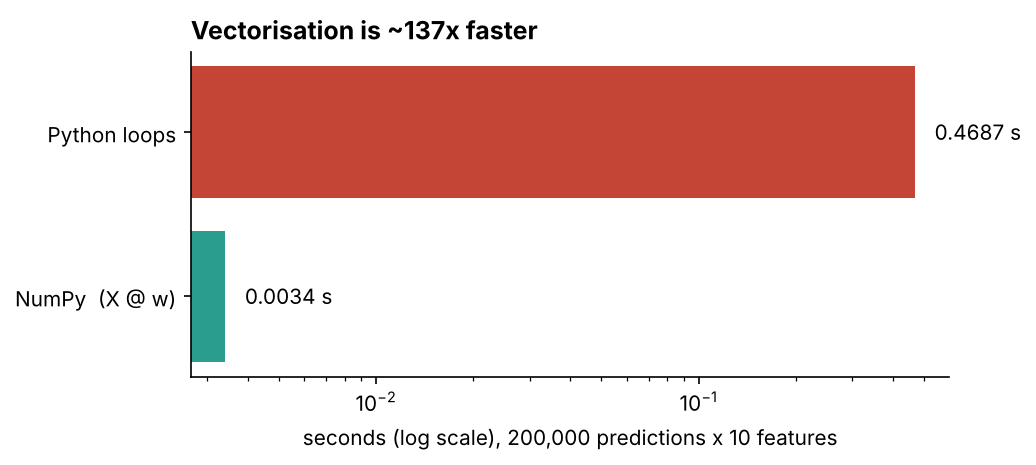

In [13]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.2), dpi=150)
bars = ax.barh(["NumPy  (X @ w)", "Python loops"], [t_vec, t_loop], color=["#2a9d8f", "#c44536"])
ax.set_xscale("log")
ax.set_xlabel("seconds (log scale), 200,000 predictions x 10 features")
ax.set_title(f"Vectorisation is ~{t_loop/t_vec:,.0f}x faster", loc="left", fontweight="bold")
for b, t in zip(bars, [t_vec, t_loop]):
    ax.text(t * 1.15, b.get_y() + b.get_height()/2, f"{t:.4f} s" if t < 1 else f"{t:.2f} s", va="center")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("assets/speed_race.png", bbox_inches="tight"); plt.show()

### Demo B: interactive loss curve. Slide the BMI weight and watch the MSE (saved to `assets/loss_slider.html`)

In [14]:
import plotly.graph_objects as go
j = 1 + data.feature_names.index("bmi")             # column of BMI in Xb
grid = np.linspace(w_scratch[j] - 60, w_scratch[j] + 60, 41)
losses = []
for g in grid:
    w_try = w_scratch.copy(); w_try[j] = g
    losses.append(mse(y, predict(Xb, w_try)))

fig = go.Figure()
fig.add_trace(go.Scatter(x=grid, y=losses, mode="lines", name="MSE(w_bmi)", line=dict(color="#264653")))
for k, g in enumerate(grid):                         # one marker trace per slider step
    fig.add_trace(go.Scatter(x=[g], y=[losses[k]], mode="markers", marker=dict(size=14, color="#e76f51"),
                             visible=(k == 20), showlegend=False))
steps = [dict(method="update", label=f"{g:.0f}",
              args=[{"visible": [True] + [i == k for i in range(len(grid))]},
                    {"title": f"w_bmi = {g:.1f}  ->  MSE = {losses[k]:,.0f}"}]) for k, g in enumerate(grid)]
fig.update_layout(title=f"w_bmi = {grid[20]:.1f}  ->  MSE = {losses[20]:,.0f}",
                  xaxis_title="weight on BMI (standardised)", yaxis_title="MSE",
                  sliders=[dict(active=20, steps=steps, currentvalue=dict(prefix="w_bmi: "))],
                  template="simple_white", height=450)
fig.write_html("assets/loss_slider.html", include_plotlyjs="cdn")
print("Saved assets/loss_slider.html: open it in a browser and screen-record the slider.")
print(f"Minimum at w_bmi = {grid[int(np.argmin(losses))]:.1f} (the gradient-zero point).")

Saved assets/loss_slider.html: open it in a browser and screen-record the slider.
Minimum at w_bmi = 24.7 (the gradient-zero point).


*The curve is a **parabola**: MSE is quadratic in each weight, so it's convex with a single minimum. That shape is why linear regression is "easy" and deep learning isn't.*

---
## 6 · Exercises (answers hidden; send me your code when ready)
Create a new notebook `lesson01_exercises.ipynb` in this folder.

1. **(Easy) Shapes:** Make `A` with shape `(4, 3)` using `np.arange(12).reshape(4, 3)`. Without running code, write down the shapes of `A.T`, `A.sum(axis=0)`, `A.sum(axis=1)`, `A @ A.T` and `A.T @ A`. Then check yourself.
2. **(Easy) Masking:** Using the diabetes data, how many patients have BMI above 30? What is their mean target vs the others'? Use one boolean mask, no loops.
3. **(Medium) Broadcasting:** Write `min_max_scale(X)` that maps every column to [0, 1] in a single vectorised expression. Verify each column's min is 0 and max is 1. Then compare with `sklearn.preprocessing.MinMaxScaler`.
4. **(Medium–Hard) Gradient descent preview:** Starting from `w = np.zeros(11)`, repeat `w = w - lr * mse_gradient(Xb, y, w)` for 500 steps with `lr = 0.1`. Plot MSE against iteration. Does it reach `w_scratch`? What happens with `lr = 1.0`? Explain why using the math.
5. **(Challenge) MAE from scratch:** Mean Absolute Error is $\frac{1}{n}\sum|\hat{y}_i - y_i|$. Derive its (sub)gradient with respect to $w$ in matrix form, implement `mae_gradient`, and run the finite-difference check from 3.7. Why does it disagree at points where a residual is exactly 0?

## 7 · Mini-quiz (answer in your message)
1. `X` has shape `(1000, 8)` and `w` has shape `(8,)`. What is the shape of `X @ w`, and what does each entry mean?
2. Why does `(X - X.mean(axis=0))` work but `(X - X.mean(axis=1))` fail for `X` of shape `(1000, 8)`?
3. In the formula $\frac{2}{n}X^\top(Xw - y)$, what is the vector $Xw - y$ called, and why is the result multiplied by $X^\top$?
4. Why do we use `np.linalg.solve(A, b)` rather than `np.linalg.inv(A) @ b`?

## 8 · Common mistakes & interview questions
**Common mistakes**
- **1-D vs 2-D confusion:** scikit-learn needs `X` as 2-D. A single feature must be `x.reshape(-1, 1)`, not shape `(n,)`.
- **Silent broadcasting bugs:** `y` of shape `(n,1)` minus `y_hat` of shape `(n,)` gives an `(n, n)` matrix, with no error raised. Always check `.shape`.
- **Python loops over samples** where a matrix operation would do.
- **Inverting matrices** (`inv`) instead of solving them: slower and numerically unstable.
- **Scaling with statistics from all the data** before splitting. This is *data leakage* (Phase 2–3). Fit the scaler on the training data only.
- **Integer arrays:** `np.array([1, 2, 3]) / 2` is fine, but in-place updates such as `a[0] = 0.5` on an int array silently truncate to 0.

**Interview questions** (practise answering out loud in under a minute each)
1. What is vectorisation, and why is it faster than a Python loop?
2. Explain broadcasting and give an example where it causes a silent bug.
3. Derive the gradient of MSE for linear regression in matrix form.
4. What are the normal equations? When would you *not* use them? (Hint: $d$ very large means $O(d^3)$ cost, and it doesn't extend to non-linear models.)
5. Why standardise features before fitting a model?
6. What does `axis=0` mean in `np.mean`?

---
### ✅ Lesson 1 checklist
- [ ] Environment set up, notebook runs top to bottom
- [ ] Exercises 1–5 attempted
- [ ] Quiz answered
- [ ] Charts in `assets/` + write-up posted (see `SOCIAL_PACK.md`)
- [ ] `git commit` + `git push`

**Next lesson:** NumPy II: random number generation, `linalg` (eigenvalues → the road to PCA), and simulating datasets.